In [14]:
import roboticstoolbox as rtb
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = [
    'SimHei', 'Microsoft YaHei', 'Arial Unicode MS', 'DejaVu Sans'
]
plt.rcParams['axes.unicode_minus'] = False

puma = rtb.models.DH.Puma560()

dt = 0.01
T_total = 5.0
steps = int(round(T_total / dt))
times = np.linspace(0.0, T_total, steps + 1)

# 使用 nominal 姿态；复制数组，避免修改模型的预设值
q = puma.qn.copy()
p_start = puma.fkine(q).A[:3, 3].copy()

radius = 0.03
circle_center = p_start + np.array([radius, 0.0, 0.0])

# 位置反馈增益，单位为 1/s
Kp = np.diag([5.0, 5.0, 5.0])

# 关节速度上限，单位为 rad/s
dq_max = 1.5

# 阻尼伪逆参数
sigma_threshold = 0.03
lambda_min = 1e-4
lambda_max = 0.02

pos_log = []
des_pos_log = []
error_log = []
time_log = []
q_log = []
dq_log = []
sigma_log = []
speed_scale_log = []

print("初始化完成")

初始化完成


In [15]:
for i, t in enumerate(times):
    # 五次时间缩放：起点和终点的目标速度、加速度均为零
    s = t / T_total
    h = 10*s**3 - 15*s**4 + 6*s**5
    h_dot = (30*s**2 - 60*s**3 + 30*s**4) / T_total

    theta = 2 * np.pi * h
    theta_dot = 2 * np.pi * h_dot

    # 从当前末端位置出发，完整画一圈
    p_d = circle_center + np.array([
        -radius * np.cos(theta),
         radius * np.sin(theta),
         0.0
    ])

    # 目标末端速度：位置轨迹的解析导数
    v_d = np.array([
        radius * np.sin(theta) * theta_dot,
        radius * np.cos(theta) * theta_dot,
        0.0
    ])

    p_cur = puma.fkine(q).A[:3, 3]
    e = p_d - p_cur

    # 速度前馈 + 位置反馈，避免高增益误差差分引起振荡
    dx_cmd = v_d + Kp @ e

    # 基坐标系下的位置雅可比：3 × 6
    J = puma.jacob0(q)[:3, :]

    # 根据最小奇异值调整阻尼
    sigma_min = np.linalg.svd(J, compute_uv=False)[-1]
    ratio = np.clip(sigma_min / sigma_threshold, 0.0, 1.0)
    damping = lambda_min + (
        lambda_max - lambda_min
    ) * (1.0 - ratio**2)

    # DLS：dq = J.T @ inv(J @ J.T + λ²I) @ dx_cmd
    dq = J.T @ np.linalg.solve(
        J @ J.T + damping**2 * np.eye(3),
        dx_cmd
    )

    # 整体缩放关节速度，保留关节速度之间的比例
    speed_scale = max(1.0, np.max(np.abs(dq)) / dq_max)
    dq = dq / speed_scale

    # 所有日志对应同一时刻的状态
    time_log.append(t)
    pos_log.append(p_cur.copy())
    des_pos_log.append(p_d.copy())
    error_log.append(np.linalg.norm(e))
    q_log.append(q.copy())
    sigma_log.append(sigma_min)

    # 最后一个时刻只记录状态，不再向后积分
    if i < steps:
        dq_log.append(dq.copy())
        speed_scale_log.append(speed_scale)
        q = q + dq * (times[i + 1] - t)

print("仿真完成")

仿真完成


In [16]:
import numpy as np

# 将仿真得到的日志列表转换为 numpy 数组
time_arr = np.asarray(time_log, dtype=float)
pos_arr = np.asarray(pos_log, dtype=float)
des_pos_arr = np.asarray(des_pos_log, dtype=float)

# 重新计算三维位置误差
error_arr = np.linalg.norm(des_pos_arr - pos_arr, axis=1)
print("数据转换完成，现在可以运行绘图代码了！")

数据转换完成，现在可以运行绘图代码了！


英文版论文图片生成完毕！


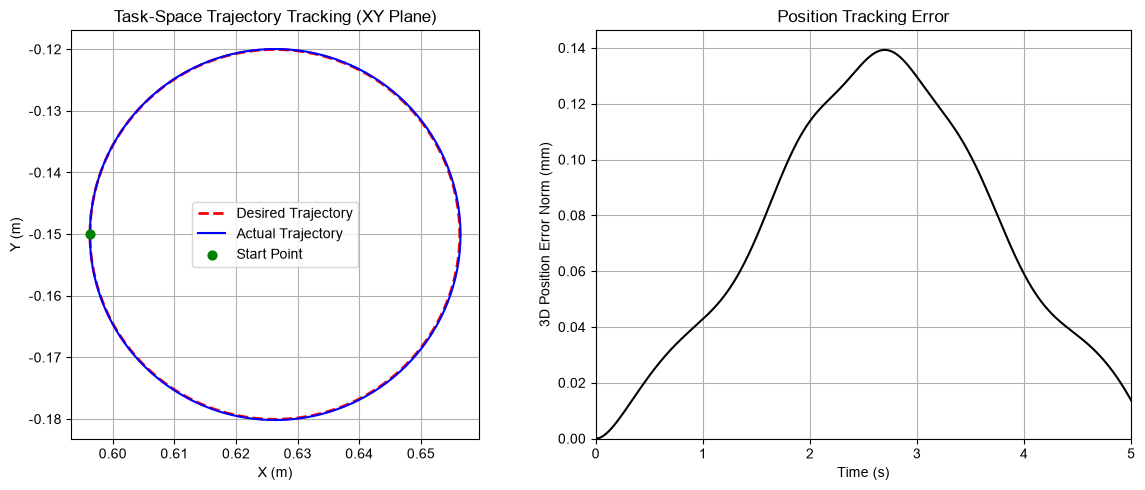

In [17]:
import matplotlib.pyplot as plt

# 强制使用英文标准字体，避免中文乱码
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left plot: XY trajectory
axes[0].plot(des_pos_arr[:, 0], des_pos_arr[:, 1], 'r--', linewidth=2, label='Desired Trajectory')
axes[0].plot(pos_arr[:, 0], pos_arr[:, 1], 'b-', linewidth=1.5, label='Actual Trajectory')
axes[0].scatter(pos_arr[0, 0], pos_arr[0, 1], color='green', s=40, label='Start Point', zorder=5)
axes[0].set_xlabel('X (m)')
axes[0].set_ylabel('Y (m)')
axes[0].set_title('Task-Space Trajectory Tracking (XY Plane)')
axes[0].set_aspect('equal', adjustable='box')
axes[0].legend()
axes[0].grid(True)

# Right plot: Error convergence
axes[1].plot(time_arr, error_arr * 1000, 'k-', linewidth=1.5)
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('3D Position Error Norm (mm)')
axes[1].set_title('Position Tracking Error')
axes[1].set_xlim(time_arr[0], time_arr[-1])
axes[1].set_ylim(bottom=0)
axes[1].grid(True)

fig.tight_layout()
fig.savefig('trajectory_tracking.png', dpi=300, bbox_inches='tight')
print("英文版论文图片生成完毕！")